# EEG Research

This project studies EEG recorded during surgery from two subjects, 014 and 015. Each subject has three recordings:

- **Baseline** — before anesthesia
- **IFT** — anesthesia induction
- **Cut** — the first surgical incision

The sampling rate is 500 Hz. The goal of the project is to compare the EEG across these stages. This notebook only loads the full recordings and checks how much usable signal each file contains. Later steps can filter the signals and estimate their spectra. Those steps are not done here.

The incision files are named `surgery` on disk. The loading function maps that name to the Cut condition. There is no time column: each row is one sample, in recording order.


## 1. Data Loading and Initial Inspection

Analysis functions live in `eeg_analysis.py`. This notebook only calls them.

In [1]:
%matplotlib inline

from pathlib import Path
import importlib
import sys

project_dir = Path.cwd()
if str(project_dir) in sys.path:
    sys.path.remove(str(project_dir))
sys.path.insert(0, str(project_dir))

import eeg_analysis as eeg
eeg = importlib.reload(eeg)


Load every CSV in `data/`. Channel columns are detected from the header, so the number of EEG channels is not hardcoded. Missing values stay as NaN. Non-numeric cells, if any, are counted and left unchanged.

In [2]:
dataset = eeg.load_recordings(project_dir / "data")
print(f"Sampling rate: {dataset['sampling_rate_hz']} Hz")
print(f"Recordings: {len(dataset['recordings'])}")


Sampling rate: 500 Hz
Recordings: 6


The table below is one row per recording. Duration is the number of samples divided by 500 Hz. A channel "with data" has at least one numeric sample. Channels listed as completely missing are NaN from start to end. `n_invalid_values` counts cells that are not numeric and not missing; those cells are not replaced.

In [3]:
summary = eeg.recording_summary(dataset)
summary_view = summary.copy()
summary_view["duration_seconds"] = summary_view["duration_seconds"].round(3)
summary_view["missing_percent"] = summary_view["missing_percent"].round(3)
summary_view


,subject_id,condition,source_file,n_samples,duration_seconds,n_channels,n_channels_with_data,n_missing_values,missing_percent,completely_missing_channels,n_invalid_values
0,014,Baseline,014_baseline_filtered.csv,15001,30.002,18,16,30002,11.111,"Ch17, Ch18",0
1,014,IFT,014_IFT_filtered.csv,15921,31.842,18,16,31884,11.126,"Ch17, Ch18",0
2,014,Cut,014_surgery_filtered_labelled.csv,150001,300.002,18,16,316662,11.728,"Ch17, Ch18",0
3,015,Baseline,015_baseline_filtered.csv,15001,30.002,18,16,30002,11.111,"Ch17, Ch18",0
4,015,IFT,015_IFT_filtered.csv,50711,101.422,18,15,152366,16.692,"Ch10, Ch17, Ch18",0
5,015,Cut,015_surgery_filtered_labelled.csv,150001,300.002,18,16,472310,17.493,"Ch17, Ch18",0


Missing-value percentage for each channel. A value of 100 means the channel is empty in that recording. A value of 0 means every sample is present.

In [4]:
missing_by_channel = eeg.missing_percent_by_channel(dataset)
missing_by_channel.round(3)


,Ch1,Ch2,Ch3,Ch4,Ch5,Ch6,Ch7,Ch8,Ch9,Ch10,Ch11,Ch12,Ch13,Ch14,Ch15,Ch16,Ch17,Ch18
014_Baseline,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,100.0,100.0
014_IFT,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.264,100.0,100.0
014_Cut,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,11.107,100.0,100.0
015_Baseline,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,100.0,100.0
015_IFT,0.000,0.000,0.000,0.014,0.000,0.000,0.000,0.000,0.000,100.000,0.000,0.000,0.446,0.000,0.000,0.000,100.0,100.0
015_Cut,15.078,14.472,4.599,0.151,10.761,6.591,3.963,0.371,8.343,3.193,13.369,3.579,1.025,11.527,7.649,10.202,100.0,100.0


The same percentages are shown below as one heatmap, so the six recordings can be compared without a separate plot per channel.

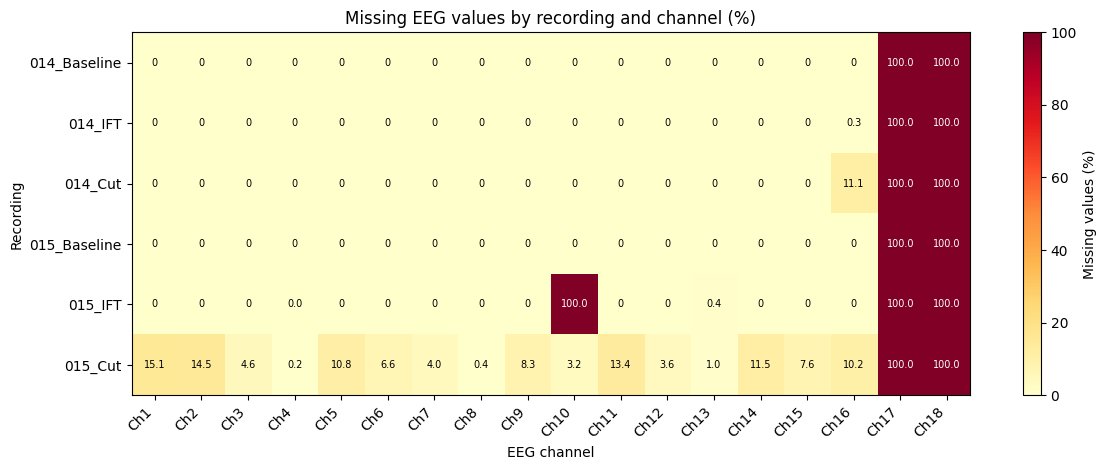

In [5]:
fig = eeg.plot_missing_percentages(dataset)


### How to read these results

All six files contain the same 18 channel columns, `Ch1`–`Ch18`, and no time or metadata columns. No non-numeric values were found, so every non-missing cell is a real EEG sample.

**How long each recording is**

| Recording | Samples | Duration |
| --- | ---: | ---: |
| 014 Baseline | 15,001 | 30.002 s |
| 014 IFT | 15,921 | 31.842 s |
| 014 Cut | 150,001 | 300.002 s |
| 015 Baseline | 15,001 | 30.002 s |
| 015 IFT | 50,711 | 101.422 s |
| 015 Cut | 150,001 | 300.002 s |

The two Cut recordings are about ten times longer than the baselines. The two IFT recordings also differ in length (31.842 s versus 101.422 s). Comparisons later in the project should keep this in mind.

**Where the missing values are**

`Ch17` and `Ch18` are completely empty in every recording. They hold no usable signal and are the natural candidates to drop before any later analysis. Because those two channels are 2 of 18 columns, even a recording that is otherwise complete is 11.111% missing.

Beyond those two channels:

- Both **Baseline** recordings are complete on `Ch1`–`Ch16`. Sixteen channels contain data.
- **014 IFT** is almost complete on `Ch1`–`Ch16`. The only extra gap is 42 samples on `Ch16` (0.264%). Sixteen channels contain data.
- **014 Cut** is complete on `Ch1`–`Ch15`. `Ch16` is missing 11.107% of its samples. Sixteen channels contain data.
- **015 IFT** has a third empty channel: `Ch10` is missing for the whole recording. `Ch4` has 7 missing samples (0.014%) and `Ch13` has 226 (0.446%). Fifteen channels contain data.
- **015 Cut** is the only recording with gaps spread across `Ch1`–`Ch16`. Every one of those channels is partly missing, from 0.151% (`Ch4`) to 15.078% (`Ch1`). The larger gaps are on `Ch1` (15.078%), `Ch2` (14.472%), `Ch11` (13.369%), `Ch14` (11.527%), `Ch5` (10.761%), and `Ch16` (10.202%). `Ch17` and `Ch18` are still the only channels that are completely empty, so sixteen channels still contain some data. The overall missing rate for this file is 17.493%.

Missing data is therefore concentrated, not uniform. It sits in two channels that are empty everywhere (`Ch17`, `Ch18`), in one extra empty channel for 015 IFT (`Ch10`), in a moderate `Ch16` gap for 014 Cut, and in widespread partial gaps for 015 Cut. The other recordings are effectively complete once `Ch17` and `Ch18` are set aside.


## 3. Missing Data Imputation

Later spectral analysis needs a value at every time point that we choose to keep. The missing stretches found in Step 2 are not all the same length, so they are not all filled in the same way.

This section reconstructs only the gaps that still have observed samples on both sides. The original recordings are not changed. Each result below is a copy.


### 3.1 Imputation Methods

A single missing sample is filled by linear interpolation. The new value lies on the straight line between the nearest observed sample before the gap and the nearest observed sample after it.

Short gaps, from 2 to 50 samples, are filled with PCHIP (`scipy.interpolate.PchipInterpolator`). PCHIP is a shape-preserving interpolant. It follows the observed samples without the overshoot that a cubic spline can produce.

Medium gaps, from 51 to 250 samples (102–500 ms), are also filled with PCHIP, but only as a provisional baseline. A gap of that length can hide real EEG changes, so these values are not treated as recovered signal.

Long gaps, more than 250 samples, are left as NaN. A completely missing channel is also left as NaN and stays out of later analysis of that channel. The cutoffs of 1, 50, and 250 samples are choices for this project. They are not thresholds taken from the papers.


In [6]:
import matplotlib.pyplot as plt
import pandas as pd

gap_summary, gap_details, gap_fig = eeg.classify_missing_gaps(dataset)
plt.close(gap_fig)

imputed_recordings = {}
gap_logs = {}
summary_rows = []
for record in gap_summary.itertuples(index=False):
    key = f"{record.subject_id}_{record.condition}"
    recording = dataset["recordings"][key]
    rows = gap_details[
        (gap_details["subject_id"] == record.subject_id)
        & (gap_details["condition"] == record.condition)
    ]
    imputed, log, summary = eeg.impute_recording(recording["eeg"], rows)
    imputed_recordings[key] = imputed
    gap_logs[key] = log
    summary_rows.append(summary)

imputation_summary = pd.DataFrame(summary_rows)


In [7]:
imputation_summary


,subject_id,condition,n_missing_original,n_linear_samples,n_pchip_samples,n_missing_remaining,n_skipped_gaps,n_provisional_gaps
0,014,Baseline,30002,0,0,30002,2,0
1,014,IFT,31884,0,42,31842,2,0
2,014,Cut,316662,12,16648,300002,2,92
3,015,Baseline,30002,0,0,30002,2,0
4,015,IFT,152366,0,233,152133,3,3
5,015,Cut,472310,183,132114,340013,117,712


### 3.2 What the Figure Shows

The figure uses 014 Cut, channel `Ch16`, because that channel contains both a short gap and a medium gap. The black line is the original signal, so it breaks where samples were missing. The red line is the interpolated segment, and the shaded band marks the samples that were filled. The lower panel is a provisional medium-gap reconstruction, not a checked recovery of the EEG.


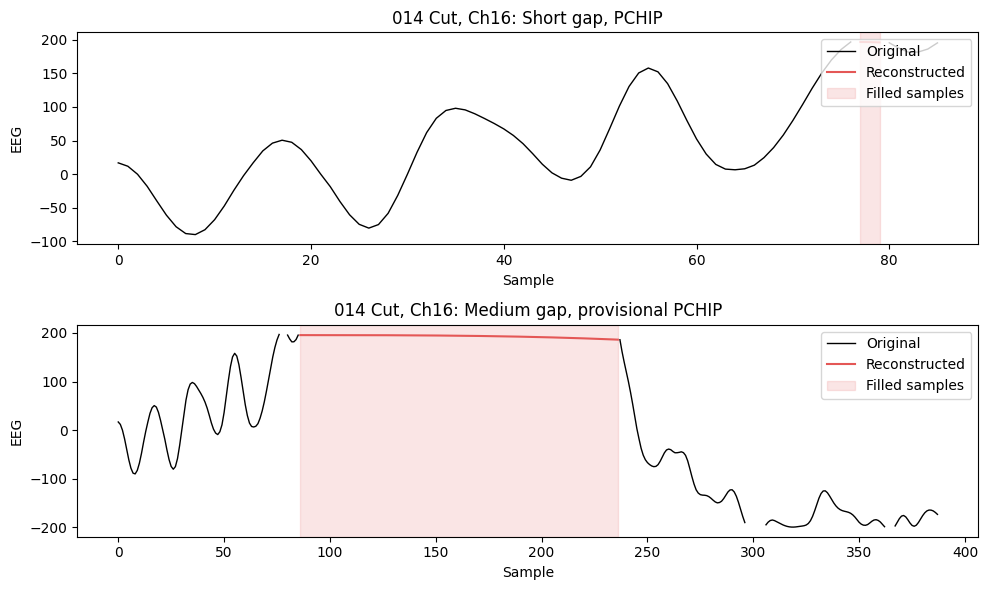

In [8]:
example_fig = eeg.plot_imputation_example(
    dataset["recordings"]["014_Cut"]["eeg"],
    imputed_recordings["014_Cut"],
    gap_logs["014_Cut"],
)


### 3.3 Results and Interpretation

No originally observed sample was changed. Filled samples plus the samples that remain missing equal the original missing-sample count in every recording.

Both baseline recordings had nothing to fill. Their only missing data are `Ch17` and `Ch18`, which stay empty (30,002 missing samples in each file).

014 IFT: 42 samples in two short gaps on `Ch16` were filled with PCHIP. The two empty channels remain missing.

014 Cut: 12 single-sample gaps were filled by linear interpolation, and 16,648 samples were filled with PCHIP. Those PCHIP samples include 92 medium gaps, which are provisional. The only skipped gaps are `Ch17` and `Ch18`. Every partial gap on `Ch16` was filled. 300,002 samples remain missing, all of them in the two empty channels.

015 IFT: 233 samples were filled with PCHIP. Three of those gaps are provisional medium gaps, on `Ch13`. `Ch10`, `Ch17`, and `Ch18` stay empty, so 152,133 samples remain missing.

015 Cut has the largest reconstruction and the largest exclusion. Linear interpolation filled 183 single samples. PCHIP filled 132,114 samples, including 712 provisional medium gaps. The 115 long gaps were not filled. Together with `Ch17` and `Ch18`, they leave 340,013 samples missing. Those long gaps are the ones that should not be passed to a spectral estimate as if they were real EEG.

The filled values, especially the medium gaps, still need a quality check. They are interpolated numbers, not measurements.


### 3.4 Methodology and Limitations

The 2026 scoping review of EEG gap imputation is the reason more than one reconstruction method is used, and the reason gap length decides which method is tried. The 2022 SRI-EEG paper is the reason the original missing locations are kept in the gap log. This step does not implement the SRI-EEG model, and it does not use a neural network.

Linear interpolation and PCHIP do not guarantee that the missing EEG has been recovered. They only draw a curve through the samples that remain. Medium gaps are a provisional baseline for that reason. The next step is to compare those medium-gap PCHIP values with a multivariate autoregressive reconstruction, where that comparison is feasible, before any frequency-domain analysis.


### 3.5 Remaining missing values

The heatmap below uses the same display as the first inspection, applied to the recordings after imputation. A cell is the percentage of samples that are still missing. Filled gaps become 0. Long gaps and completely empty channels stay above 0.


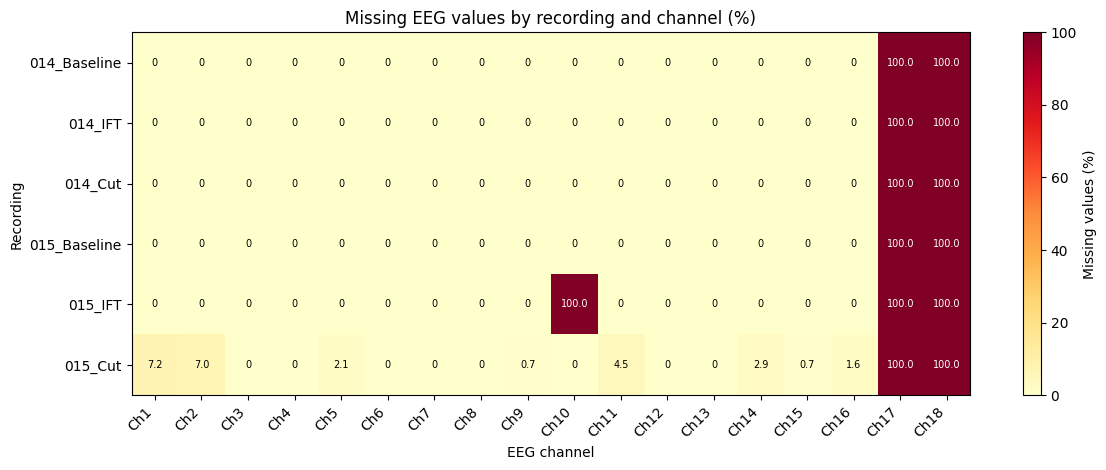

In [9]:
imputed_dataset = {
    "sampling_rate_hz": dataset["sampling_rate_hz"],
    "recordings": {
        key: {
            "subject_id": dataset["recordings"][key]["subject_id"],
            "condition": dataset["recordings"][key]["condition"],
            "eeg": imputed,
        }
        for key, imputed in imputed_recordings.items()
    },
}
missing_after_fig = eeg.plot_missing_percentages(imputed_dataset)


## 4. Band-pass Filtering (1–40 Hz)

### 4.1 Objective

Slow changes below 1 Hz are mostly baseline drift. They move the whole trace up and down without being part of the rhythms we will analyze later. Activity above 40 Hz is mostly high-frequency noise relative to those rhythms. A band-pass filter reduces both before any frequency analysis.


### 4.2 Method

The filter is a 4th-order Butterworth band-pass from 1 Hz to 40 Hz, applied at the 500 Hz sampling rate. `sosfiltfilt` runs that filter forward and then backward. The backward pass removes the time shift, so peaks stay at the same sample.

Filtering changes the value of each sample inside a continuous stretch. It does not delete samples, and it does not fill missing ones. Each run of finite samples is filtered on its own. A NaN gap is not crossed. A run shorter than the padding this filter needs is left at its Step 3 values. A 4th-order Butterworth does not stop exactly at 1 Hz and 40 Hz, so some energy just outside the band remains.


In [10]:
filtered_recordings = {}
filter_counts = []
for key, imputed in imputed_recordings.items():
    filtered, counts = eeg.bandpass_recording(imputed)
    filtered_recordings[key] = filtered
    filter_counts.append({"recording": key, **counts})

filter_summary = pd.DataFrame(filter_counts)
filter_summary


,recording,n_segments_filtered,n_segments_too_short
0,014_Baseline,16,0
1,014_IFT,16,0
2,014_Cut,16,0
3,015_Baseline,16,0
4,015_IFT,15,0
5,015_Cut,114,17


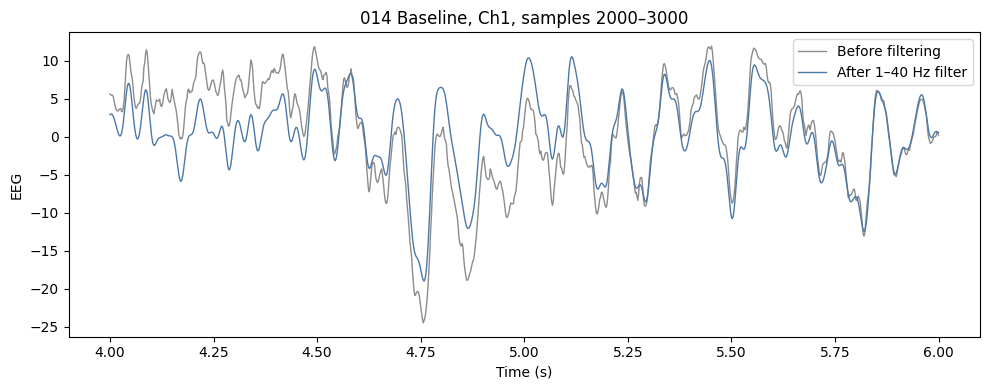

In [11]:
import matplotlib.pyplot as plt
import numpy as np

channel = "Ch1"
start, end = 2000, 3000
time_seconds = np.arange(start, end + 1) / dataset["sampling_rate_hz"]
before = imputed_recordings["014_Baseline"][channel].iloc[start:end + 1]
after = filtered_recordings["014_Baseline"][channel].iloc[start:end + 1]

fig, axis = plt.subplots(figsize=(10, 4))
axis.plot(time_seconds, before, color="0.55", linewidth=1, label="Before filtering")
axis.plot(time_seconds, after, color="#4C78A8", linewidth=1, label="After 1–40 Hz filter")
axis.set_xlabel("Time (s)")
axis.set_ylabel("EEG")
axis.set_title("014 Baseline, Ch1, samples 2000–3000")
axis.legend()
fig.tight_layout()


### 4.3 Interpretation

On this two-second stretch of 014 Baseline, `Ch1`, the filtered line is smoother than the imputed line. The large slow wander is smaller, and the fastest jitter is smaller, because those parts of the signal sit outside 1–40 Hz.

The cutoff is not a hard wall. A 4th-order Butterworth only attenuates frequencies outside the passband, so a little energy below 1 Hz and above 40 Hz remains. The band that is kept still covers the rhythms planned for the later frequency analysis.

Removing everything below 1 Hz also removes slow EEG activity that can be physiologically real. That is a limit of this choice, not a claim that those slow components were only drift. In 015 Cut, 17 finite segments were shorter than the filter padding, so they were left unfiltered. Long gaps and `Ch17` and `Ch18` are still NaN.
